In [1]:
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB

In [2]:
def sigbar(x1, x2, y, p, fontsize = 10, lw = 1.5):

    plt.hlines(y, x1, x2, lw = lw, colors = 'k')
    if p < 0.001: text = '***'
    elif p < 0.01: text = '**'
    elif p < 0.05: text = '*'
    else: text = 'n.s.'
    plt.text(x = (x1+x2)/2, y = y, s = text, fontsize = fontsize, ha = 'center', va = 'bottom')

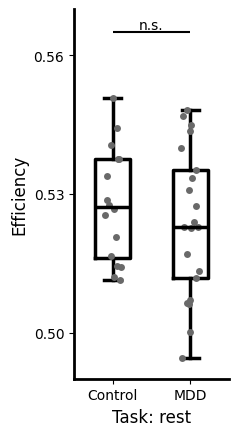

In [3]:
metric = 'global_effi'
task = 'rest'

res = pd.read_csv('../results/fig06/graphical_res_MDD_MMP(distance_ridge).csv')
res = res[abs(res['lambda'] - 0.7) < 1e-3]; res = res[res['FILE_ID'].str.contains(task, na = False)]
res_con = res[res['FILE_ID'].str.contains('sub-HVS', na = False)]
res_mdd = res[res['FILE_ID'].str.contains('sub-T', na = False)]

plt.figure(figsize = (2.0, 4.8)); ax = plt.gca()
box = ax.boxplot([res_con[metric].values, res_mdd[metric].values], widths = 0.45, showfliers = False)
for i, color in enumerate(['k', 'k']):
    box['boxes'][i].set_color(color); box['boxes'][i].set_linewidth(2.5)
    box['medians'][i].set_color(color); box['medians'][i].set_linewidth(2.5)
    box['whiskers'][2*i].set_color(color); box['whiskers'][2*i].set_linewidth(2.5); box['caps'][2*i].set_color(color); box['caps'][2*i].set_linewidth(2.5)
    box['whiskers'][2*i+1].set_color(color); box['whiskers'][2*i+1].set_linewidth(2.5); box['caps'][2*i+1].set_color(color); box['caps'][2*i+1].set_linewidth(2.5)
jittered_x = 1 + np.random.uniform(-0.12, 0.12, size = len(res_con[metric].values))
ax.scatter(x = jittered_x, y = res_con[metric].values, color = 'dimgray', s = 25, linewidths = 0, zorder = 2)
jittered_x = 2 + np.random.uniform(-0.12, 0.12, size = len(res_mdd[metric].values))
ax.scatter(x = jittered_x, y = res_mdd[metric].values, color = 'dimgray', s = 25, linewidths = 0, zorder = 2)

pval = mannwhitneyu(res_con[metric].values, res_mdd[metric].values)[1]
sigbar(1, 2, 0.565, pval)

plt.xlabel('Task: {}'.format(task), fontsize = 12); plt.xlim(0.5, 2.5); plt.xticks([1, 2], ['Control', 'MDD'], fontsize = 10)
plt.ylabel('Efficiency', fontsize = 12); plt.ylim(0.49, 0.57); plt.yticks([0.50, 0.53, 0.56], fontsize = 10)
ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(2); ax.spines['bottom'].set_linewidth(2)

plt.show()

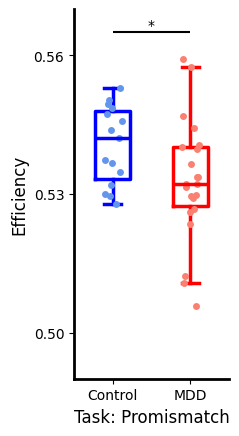

In [4]:
metric = 'global_effi'
task = 'Promismatch'

res = pd.read_csv('../results/fig06/graphical_res_MDD_MMP(distance_ridge).csv')
res = res[abs(res['lambda'] - 0.7) < 1e-3]; res = res[res['FILE_ID'].str.contains(task, na = False)]
res_con = res[res['FILE_ID'].str.contains('sub-HVS', na = False)]
res_mdd = res[res['FILE_ID'].str.contains('sub-T', na = False)]

plt.figure(figsize = (2.0, 4.8)); ax = plt.gca()
box = ax.boxplot([res_con[metric].values, res_mdd[metric].values], widths = 0.45, showfliers = False)
for i, color in enumerate(['b', 'r']):
    box['boxes'][i].set_color(color); box['boxes'][i].set_linewidth(2.5)
    box['medians'][i].set_color(color); box['medians'][i].set_linewidth(2.5)
    box['whiskers'][2*i].set_color(color); box['whiskers'][2*i].set_linewidth(2.5); box['caps'][2*i].set_color(color); box['caps'][2*i].set_linewidth(2.5)
    box['whiskers'][2*i+1].set_color(color); box['whiskers'][2*i+1].set_linewidth(2.5); box['caps'][2*i+1].set_color(color); box['caps'][2*i+1].set_linewidth(2.5)
jittered_x = 1 + np.random.uniform(-0.12, 0.12, size = len(res_con[metric].values))
ax.scatter(x = jittered_x, y = res_con[metric].values, color = 'cornflowerblue', s = 25, linewidths = 0, zorder = 2)
jittered_x = 2 + np.random.uniform(-0.12, 0.12, size = len(res_mdd[metric].values))
ax.scatter(x = jittered_x, y = res_mdd[metric].values, color = 'salmon', s = 25, linewidths = 0, zorder = 2)

pval = mannwhitneyu(res_con[metric].values, res_mdd[metric].values)[1]
sigbar(1, 2, 0.565, pval)

plt.xlabel('Task: {}'.format(task), fontsize = 12); plt.xlim(0.5, 2.5); plt.xticks([1, 2], ['Control', 'MDD'], fontsize = 10)
plt.ylabel('Efficiency', fontsize = 12); plt.ylim(0.49, 0.57); plt.yticks([0.50, 0.53, 0.56], fontsize = 10)
ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(2); ax.spines['bottom'].set_linewidth(2)

plt.show()

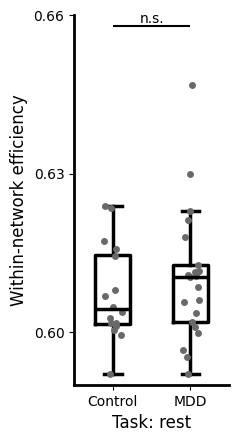

In [5]:
metric = 'intra_effi'
task = 'rest'

res = pd.read_csv('../results/fig06/graphical_res_MDD_MMP(distance_ridge).csv')
res = res[abs(res['lambda'] - 0.7) < 1e-3]; res = res[res['FILE_ID'].str.contains(task, na = False)]
res_con = res[res['FILE_ID'].str.contains('sub-HVS', na = False)]
res_mdd = res[res['FILE_ID'].str.contains('sub-T', na = False)]

plt.figure(figsize = (2.0, 4.8)); ax = plt.gca()
box = ax.boxplot([res_con[metric].values, res_mdd[metric].values], widths = 0.45, showfliers = False)
for i, color in enumerate(['k', 'k']):
    box['boxes'][i].set_color(color); box['boxes'][i].set_linewidth(2.5)
    box['medians'][i].set_color(color); box['medians'][i].set_linewidth(2.5)
    box['whiskers'][2*i].set_color(color); box['whiskers'][2*i].set_linewidth(2.5); box['caps'][2*i].set_color(color); box['caps'][2*i].set_linewidth(2.5)
    box['whiskers'][2*i+1].set_color(color); box['whiskers'][2*i+1].set_linewidth(2.5); box['caps'][2*i+1].set_color(color); box['caps'][2*i+1].set_linewidth(2.5)
jittered_x = 1 + np.random.uniform(-0.12, 0.12, size = len(res_con[metric].values))
ax.scatter(x = jittered_x, y = res_con[metric].values, color = 'dimgray', s = 25, linewidths = 0, zorder = 2)
jittered_x = 2 + np.random.uniform(-0.12, 0.12, size = len(res_mdd[metric].values))
ax.scatter(x = jittered_x, y = res_mdd[metric].values, color = 'dimgray', s = 25, linewidths = 0, zorder = 2)

pval = mannwhitneyu(res_con[metric].values, res_mdd[metric].values)[1]
sigbar(1, 2, 0.658, pval)

plt.xlabel('Task: {}'.format(task), fontsize = 12); plt.xlim(0.5, 2.5); plt.xticks([1, 2], ['Control', 'MDD'], fontsize = 10)
plt.ylabel('Within-network efficiency', fontsize = 12); plt.ylim(0.59, 0.66); plt.yticks([0.60, 0.63, 0.66], fontsize = 10)
ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(2); ax.spines['bottom'].set_linewidth(2)

plt.show()

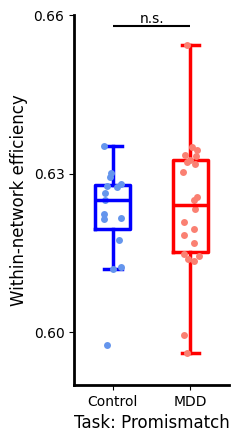

In [6]:
metric = 'intra_effi'
task = 'Promismatch'

res = pd.read_csv('../results/fig06/graphical_res_MDD_MMP(distance_ridge).csv')
res = res[abs(res['lambda'] - 0.7) < 1e-3]; res = res[res['FILE_ID'].str.contains(task, na = False)]
res_con = res[res['FILE_ID'].str.contains('sub-HVS', na = False)]
res_mdd = res[res['FILE_ID'].str.contains('sub-T', na = False)]

plt.figure(figsize = (2.0, 4.8)); ax = plt.gca()
box = ax.boxplot([res_con[metric].values, res_mdd[metric].values], widths = 0.45, showfliers = False)
for i, color in enumerate(['b', 'r']):
    box['boxes'][i].set_color(color); box['boxes'][i].set_linewidth(2.5)
    box['medians'][i].set_color(color); box['medians'][i].set_linewidth(2.5)
    box['whiskers'][2*i].set_color(color); box['whiskers'][2*i].set_linewidth(2.5); box['caps'][2*i].set_color(color); box['caps'][2*i].set_linewidth(2.5)
    box['whiskers'][2*i+1].set_color(color); box['whiskers'][2*i+1].set_linewidth(2.5); box['caps'][2*i+1].set_color(color); box['caps'][2*i+1].set_linewidth(2.5)
jittered_x = 1 + np.random.uniform(-0.12, 0.12, size = len(res_con[metric].values))
ax.scatter(x = jittered_x, y = res_con[metric].values, color = 'cornflowerblue', s = 25, linewidths = 0, zorder = 2)
jittered_x = 2 + np.random.uniform(-0.12, 0.12, size = len(res_mdd[metric].values))
ax.scatter(x = jittered_x, y = res_mdd[metric].values, color = 'salmon', s = 25, linewidths = 0, zorder = 2)

pval = mannwhitneyu(res_con[metric].values, res_mdd[metric].values)[1]
sigbar(1, 2, 0.658, pval)

plt.xlabel('Task: {}'.format(task), fontsize = 12); plt.xlim(0.5, 2.5); plt.xticks([1, 2], ['Control', 'MDD'], fontsize = 10)
plt.ylabel('Within-network efficiency', fontsize = 12); plt.ylim(0.59, 0.66); plt.yticks([0.60, 0.63, 0.66], fontsize = 10)
ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(2); ax.spines['bottom'].set_linewidth(2)

plt.show()

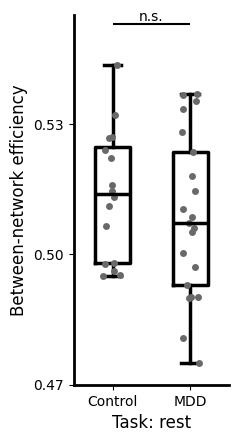

In [7]:
metric = 'inter_effi'
task = 'rest'

res = pd.read_csv('../results/fig06/graphical_res_MDD_MMP(distance_ridge).csv')
res = res[abs(res['lambda'] - 0.7) < 1e-3]; res = res[res['FILE_ID'].str.contains(task, na = False)]
res_con = res[res['FILE_ID'].str.contains('sub-HVS', na = False)]
res_mdd = res[res['FILE_ID'].str.contains('sub-T', na = False)]

plt.figure(figsize = (2.0, 4.8)); ax = plt.gca()
box = ax.boxplot([res_con[metric].values, res_mdd[metric].values], widths = 0.45, showfliers = False)
for i, color in enumerate(['k', 'k']):
    box['boxes'][i].set_color(color); box['boxes'][i].set_linewidth(2.5)
    box['medians'][i].set_color(color); box['medians'][i].set_linewidth(2.5)
    box['whiskers'][2*i].set_color(color); box['whiskers'][2*i].set_linewidth(2.5); box['caps'][2*i].set_color(color); box['caps'][2*i].set_linewidth(2.5)
    box['whiskers'][2*i+1].set_color(color); box['whiskers'][2*i+1].set_linewidth(2.5); box['caps'][2*i+1].set_color(color); box['caps'][2*i+1].set_linewidth(2.5)
jittered_x = 1 + np.random.uniform(-0.12, 0.12, size = len(res_con[metric].values))
ax.scatter(x = jittered_x, y = res_con[metric].values, color = 'dimgray', s = 25, linewidths = 0, zorder = 2)
jittered_x = 2 + np.random.uniform(-0.12, 0.12, size = len(res_mdd[metric].values))
ax.scatter(x = jittered_x, y = res_mdd[metric].values, color = 'dimgray', s = 25, linewidths = 0, zorder = 2)

pval = mannwhitneyu(res_con[metric].values, res_mdd[metric].values)[1]
sigbar(1, 2, 0.553, pval)

plt.xlabel('Task: {}'.format(task), fontsize = 12); plt.xlim(0.5, 2.5); plt.xticks([1, 2], ['Control', 'MDD'], fontsize = 10)
plt.ylabel('Between-network efficiency', fontsize = 12); plt.ylim(0.470, 0.555); plt.yticks([0.47, 0.50, 0.53], fontsize = 10)
ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(2); ax.spines['bottom'].set_linewidth(2)

plt.show()

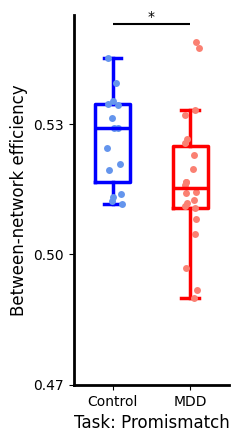

In [8]:
metric = 'inter_effi'
task = 'Promismatch'

res = pd.read_csv('../results/fig06/graphical_res_MDD_MMP(distance_ridge).csv')
res = res[abs(res['lambda'] - 0.7) < 1e-3]; res = res[res['FILE_ID'].str.contains(task, na = False)]
res_con = res[res['FILE_ID'].str.contains('sub-HVS', na = False)]
res_mdd = res[res['FILE_ID'].str.contains('sub-T', na = False)]

plt.figure(figsize = (2.0, 4.8)); ax = plt.gca()
box = ax.boxplot([res_con[metric].values, res_mdd[metric].values], widths = 0.45, showfliers = False)
for i, color in enumerate(['b', 'r']):
    box['boxes'][i].set_color(color); box['boxes'][i].set_linewidth(2.5)
    box['medians'][i].set_color(color); box['medians'][i].set_linewidth(2.5)
    box['whiskers'][2*i].set_color(color); box['whiskers'][2*i].set_linewidth(2.5); box['caps'][2*i].set_color(color); box['caps'][2*i].set_linewidth(2.5)
    box['whiskers'][2*i+1].set_color(color); box['whiskers'][2*i+1].set_linewidth(2.5); box['caps'][2*i+1].set_color(color); box['caps'][2*i+1].set_linewidth(2.5)
jittered_x = 1 + np.random.uniform(-0.12, 0.12, size = len(res_con[metric].values))
ax.scatter(x = jittered_x, y = res_con[metric].values, color = 'cornflowerblue', s = 25, linewidths = 0, zorder = 2)
jittered_x = 2 + np.random.uniform(-0.12, 0.12, size = len(res_mdd[metric].values))
ax.scatter(x = jittered_x, y = res_mdd[metric].values, color = 'salmon', s = 25, linewidths = 0, zorder = 2)

pval = mannwhitneyu(res_con[metric].values, res_mdd[metric].values)[1]
sigbar(1, 2, 0.553, pval)

plt.xlabel('Task: {}'.format(task), fontsize = 12); plt.xlim(0.5, 2.5); plt.xticks([1, 2], ['Control', 'MDD'], fontsize = 10)
plt.ylabel('Between-network efficiency', fontsize = 12); plt.ylim(0.470, 0.555); plt.yticks([0.47, 0.50, 0.53], fontsize = 10)
ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(2); ax.spines['bottom'].set_linewidth(2)

plt.show()

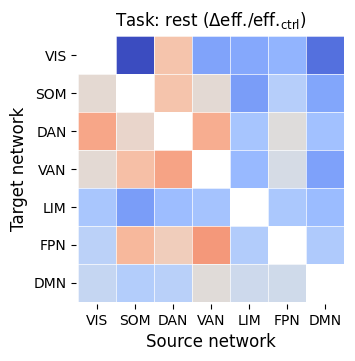

In [9]:
task = 'rest'

res = pd.read_csv('../results/fig06/graphical_res_MDD_MMP(distance_ridge).csv')
res = res[abs(res['lambda'] - 0.7) < 1e-3]; res = res[res['FILE_ID'].str.contains(task, na = False)]
res_con = res[res['FILE_ID'].str.contains('sub-HVS', na = False)]
res_mdd = res[res['FILE_ID'].str.contains('sub-T', na = False)]

network_list = ['VIS', 'SOM', 'DAN', 'VAN', 'LIM', 'FPN', 'DMN']

network_res_effi = np.zeros((7, 7)); network_sig_effi = np.zeros((7, 7))
for i in network_list:
    for j in network_list:
        if j == i: continue
        stat = '{}2{}_effi'.format(i, j)
        res_disease = res_mdd[stat].values; res_control = res_con[stat].values
        network_res_effi[network_list.index(j), network_list.index(i)] = (np.mean(res_disease) - np.mean(res_control)) / np.mean(res_control)
        network_sig_effi[network_list.index(j), network_list.index(i)] = mannwhitneyu(res_disease, res_control)[1]
np.fill_diagonal(network_res_effi, np.nan)
network_sig_effi[np.eye(7) != 1] = multipletests(network_sig_effi[np.eye(7) != 1], alpha = 0.05, method = 'fdr_bh')[1]

plt.figure(figsize = (3.5, 3.5))
plt.pcolormesh(np.flipud(network_res_effi), vmin = -0.05, vmax = 0.05, cmap = 'coolwarm')
ax = plt.gca(); ax.set_aspect('equal')
for i in range(8): plt.plot([i, i], [0, 7], lw = .5, c = 'w'); plt.plot([0, 7], [i, i], lw = .5, c = 'w')

for i in range(7):
    for j in range(7):
        if j == i: continue
        if network_sig_effi[i, j] < 0.05:
            if network_sig_effi[i, j] < 0.001: text = '***'
            elif network_sig_effi[i, j] < 0.01: text = '**'
            else: text = '*'
            plt.text(x = j+.5, y = 7-i-.5, s = text, fontsize = 10, ha = 'center', va = 'center')

ax.spines['left'].set_visible(False); ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False); ax.spines['top'].set_visible(False)
plt.xlabel('Source network', fontsize = 12); plt.xlim(-0.05, 7.05); plt.xticks(np.arange(7)+.5, network_list, fontsize = 10)
plt.ylabel('Target network', fontsize = 12); plt.ylim(-0.05, 7.05); plt.yticks(np.arange(7)[::-1]+.5, network_list, fontsize = 10)
plt.title(r'Task: rest ($\Delta$eff./eff.$_\text{ctrl}$)')

plt.show()

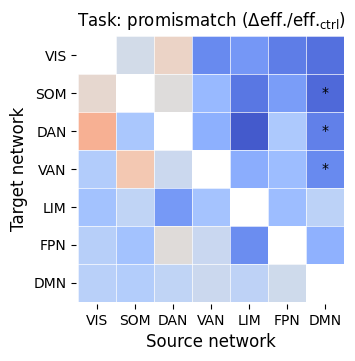

In [10]:
task = 'Promismatch'

res = pd.read_csv('../results/fig06/graphical_res_MDD_MMP(distance_ridge).csv')
res = res[abs(res['lambda'] - 0.7) < 1e-3]; res = res[res['FILE_ID'].str.contains(task, na = False)]
res_con = res[res['FILE_ID'].str.contains('sub-HVS', na = False)]
res_mdd = res[res['FILE_ID'].str.contains('sub-T', na = False)]

network_list = ['VIS', 'SOM', 'DAN', 'VAN', 'LIM', 'FPN', 'DMN']

network_res_effi = np.zeros((7, 7)); network_sig_effi = np.zeros((7, 7))
for i in network_list:
    for j in network_list:
        if j == i: continue
        stat = '{}2{}_effi'.format(i, j)
        res_disease = res_mdd[stat].values; res_control = res_con[stat].values
        network_res_effi[network_list.index(j), network_list.index(i)] = (np.mean(res_disease) - np.mean(res_control)) / np.mean(res_control)
        network_sig_effi[network_list.index(j), network_list.index(i)] = mannwhitneyu(res_disease, res_control)[1]
np.fill_diagonal(network_res_effi, np.nan)
network_sig_effi[np.eye(7) != 1] = multipletests(network_sig_effi[np.eye(7) != 1], alpha = 0.05, method = 'fdr_bh')[1]

plt.figure(figsize = (3.5, 3.5))
plt.pcolormesh(np.flipud(network_res_effi), vmin = -0.05, vmax = 0.05, cmap = 'coolwarm')
ax = plt.gca(); ax.set_aspect('equal')
for i in range(8): plt.plot([i, i], [0, 7], lw = .5, c = 'w'); plt.plot([0, 7], [i, i], lw = .5, c = 'w')

for i in range(7):
    for j in range(7):
        if j == i: continue
        if network_sig_effi[i, j] < 0.05:
            if network_sig_effi[i, j] < 0.001: text = '***'
            elif network_sig_effi[i, j] < 0.01: text = '**'
            else: text = '*'
            plt.text(x = j+.5, y = 7-i-.5, s = text, fontsize = 10, ha = 'center', va = 'center')

ax.spines['left'].set_visible(False); ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False); ax.spines['top'].set_visible(False)
plt.xlabel('Source network', fontsize = 12); plt.xlim(-0.05, 7.05); plt.xticks(np.arange(7)+.5, network_list, fontsize = 10)
plt.ylabel('Target network', fontsize = 12); plt.ylim(-0.05, 7.05); plt.yticks(np.arange(7)[::-1]+.5, network_list, fontsize = 10)
plt.title(r'Task: promismatch ($\Delta$eff./eff.$_\text{ctrl}$)')

plt.show()

In [11]:
pipe = Pipeline([('clf', GaussianNB())])

task = 'rest'
res = pd.read_csv('../results/fig06/graphical_res_MDD_MMP(distance_ridge).csv')
res = res[abs(res['lambda'] - 0.7) < 1e-3]
res = res[res['FILE_ID'].str.contains(task, na = False)]
file_list = res['FILE_ID'].values; network_list = network_list = ['VIS', 'SOM', 'DAN', 'VAN', 'LIM', 'FPN', 'DMN']
X = np.array([np.array([[res[res['FILE_ID'] == f]['{}2{}_effi'.format(i, j)] for j in network_list if j != i] for i in network_list]).flatten() for f in file_list])
y = np.array(['sub-T' in f for f in file_list]).astype(int)

probas = []; accs = []; aucs = []
for r in range(500):
    cv = StratifiedKFold(n_splits = 10, shuffle = True, random_state = r)
    proba_oof = cross_val_predict(pipe, X, y, cv = cv, method = 'predict_proba')[:, 1]
    pred_oof = (proba_oof >= 0.5).astype(int)
    probas.append(proba_oof)
    accs.append(accuracy_score(y, pred_oof))
    aucs.append(roc_auc_score(y, proba_oof))
probas_r = np.array(probas); accs = np.array(accs); aucs = np.array(aucs)

print(r'mean acc:', '{:.6f}'.format(accs.mean()))
print(r'std acc:', '{:.6f}'.format(accs.std()))
print(r'95% interval (2.5%, 97.5%):', '[{:.3f}, {:.3f}]'.format(*np.quantile(accs, [0.025, 0.975])))
print(r'mean auc:', '{:.6f}'.format(aucs.mean()))
print(r'std auc:', '{:.6f}'.format(aucs.std()))
print(r'95% interval (2.5%, 97.5%):', '[{:.3f}, {:.3f}]'.format(*np.quantile(aucs, [0.025, 0.975])))

print('------------------------------')

task = 'Promismatch'
res = pd.read_csv('../results/fig06/graphical_res_MDD_MMP(distance_ridge).csv')
res = res[abs(res['lambda'] - 0.7) < 1e-3]
res = res[res['FILE_ID'].str.contains(task, na = False)]
file_list = res['FILE_ID'].values; network_list = network_list = ['VIS', 'SOM', 'DAN', 'VAN', 'LIM', 'FPN', 'DMN']
X = np.array([np.array([[res[res['FILE_ID'] == f]['{}2{}_effi'.format(i, j)] for j in network_list if j != i] for i in network_list]).flatten() for f in file_list])
y = np.array(['sub-T' in f for f in file_list]).astype(int)

probas = []; accs = []; aucs = []
for r in range(500):
    cv = StratifiedKFold(n_splits = 10, shuffle = True, random_state = r)
    proba_oof = cross_val_predict(pipe, X, y, cv = cv, method = 'predict_proba')[:, 1]
    pred_oof = (proba_oof >= 0.5).astype(int)
    probas.append(proba_oof)
    accs.append(accuracy_score(y, pred_oof))
    aucs.append(roc_auc_score(y, proba_oof))
probas_t = np.array(probas); accs = np.array(accs); aucs = np.array(aucs)

print(r'mean acc:', '{:.6f}'.format(accs.mean()))
print(r'std acc:', '{:.6f}'.format(accs.std()))
print(r'95% interval (2.5%, 97.5%):', '[{:.3f}, {:.3f}]'.format(*np.quantile(accs, [0.025, 0.975])))
print(r'mean auc:', '{:.6f}'.format(aucs.mean()))
print(r'std auc:', '{:.6f}'.format(aucs.std()))
print(r'95% interval (2.5%, 97.5%):', '[{:.3f}, {:.3f}]'.format(*np.quantile(aucs, [0.025, 0.975])))

mean acc: 0.551946
std acc: 0.048858
95% interval (2.5%, 97.5%): [0.459, 0.649]
mean auc: 0.588667
std auc: 0.038410
95% interval (2.5%, 97.5%): [0.504, 0.658]
------------------------------
mean acc: 0.698324
std acc: 0.036419
95% interval (2.5%, 97.5%): [0.622, 0.757]
mean auc: 0.692182
std auc: 0.024538
95% interval (2.5%, 97.5%): [0.644, 0.742]


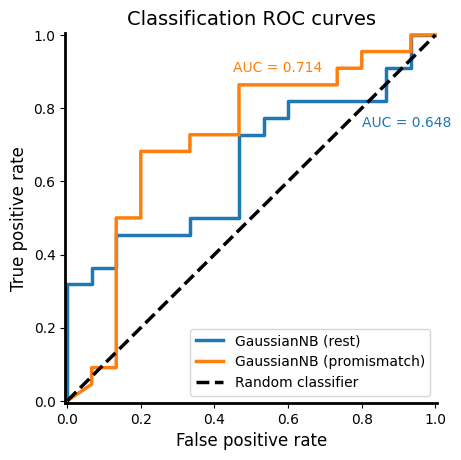

In [12]:
proba_mean = probas_r.mean(axis = 0)
auc_from_meanprob_r = roc_auc_score(y, proba_mean)
fpr_r, tpr_r, _ = roc_curve(y, proba_mean)

proba_mean = probas_t.mean(axis = 0)
auc_from_meanprob_t = roc_auc_score(y, proba_mean)
fpr_t, tpr_t, _ = roc_curve(y, proba_mean)

plt.figure(figsize = (4.8, 4.8))
plt.plot(fpr_r, tpr_r, lw = 2.5, label = 'GaussianNB (rest)')
plt.plot(fpr_t, tpr_t, lw = 2.5, label = 'GaussianNB (promismatch)')
plt.plot([0, 1], [0, 1], lw = 2.5, linestyle = '--', c = 'k', label = 'Random classifier')
plt.text(x = 0.80, y = 0.75, s = 'AUC = {:.3f}'.format(auc_from_meanprob_r), color = plt.colormaps['tab10'].colors[0], fontsize = 10)
plt.text(x = 0.45, y = 0.90, s = 'AUC = {:.3f}'.format(auc_from_meanprob_t), color = plt.colormaps['tab10'].colors[1], fontsize = 10)

plt.xlabel('False positive rate', fontsize = 12); plt.xlim(-0.005, 1.005); plt.xticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0], fontsize = 10)
plt.ylabel('True positive rate', fontsize =12); plt.ylim(-0.005, 1.005); plt.yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0], fontsize = 10)
plt.gca().spines['right'].set_visible(False); plt.gca().spines['top'].set_visible(False)
plt.gca().spines['left'].set_linewidth(2); plt.gca().spines['bottom'].set_linewidth(2)
plt.title('Classification ROC curves', fontsize = 14)
plt.legend(fontsize = 10)

plt.show()